# Apprentissage automatique from scratch

Ici, on utilise la logique actuelle du projet :

- `Dense`
- `ReLU`
- `Softmax`
- `MulticlassCrossEntropy`
- `Sequential`
- `SGD`

Le dataset change, mais la logique d'apprentissage reste celle du framework maison.


In [1]:
try:
    import google.colab
    google.colab.drive.mount('/content/drive')
except Exception:
    pass

In [2]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/learning-cifar10-from-scratch')
print(PROJECT_ROOT.exists())

DATA_ROOT = PROJECT_ROOT / 'data'
MODEL_ROOT = PROJECT_ROOT / 'models'
COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
REPO_URL = 'https://github.com/Appolinairee/scratch-deep-learning-vision.git'

for path in [DATA_ROOT, MODEL_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

False


In [3]:
import subprocess

if not (PROJECT_ROOT / '.git').exists():
    # Clone dans un tmp puis déplace le .git
    TMP = Path('/content/repo_tmp')
    subprocess.run(['git', 'clone', REPO_URL, str(TMP)], check=True)
    # Déplace uniquement le contenu (pas data/ et models/)
    subprocess.run(['rsync', '-av', '--ignore-existing', f'{TMP}/', str(PROJECT_ROOT)], check=True)
    subprocess.run(['rm', '-rf', str(TMP)], check=True)
else:
    subprocess.run(['git', '-C', str(PROJECT_ROOT), 'pull'], check=True)

In [4]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/learning-cifar10-from-scratch')
DATA_ROOT = PROJECT_ROOT / 'data'
MODEL_ROOT = PROJECT_ROOT / 'models'
COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
REPO_URL = 'https://github.com/Appolinairee/scratch-deep-learning-vision.git'

for path in [DATA_ROOT, MODEL_ROOT]:
    path.mkdir(parents=True, exist_ok=True)

In [5]:
import sys
from pathlib import Path

# Ensure PROJECT_ROOT is defined; if not, find repo root by locating 'src' folder
try:
    PROJECT_ROOT
except NameError:
    repo_root = Path.cwd()
    while not (repo_root / "src").exists() and repo_root.parent != repo_root:
        repo_root = repo_root.parent
    PROJECT_ROOT = repo_root

# On Colab we may want a convenience symlink, but it's optional and may fail due to permissions
if 'google.colab' in sys.modules:
    COLAB_ROOT = Path('/content/learning-cifar10-from-scratch')
    try:
        if not COLAB_ROOT.exists():
            COLAB_ROOT.symlink_to(PROJECT_ROOT)
    except Exception as e:
        print('Could not create symlink:', e)

# Ensure the project root is on sys.path so `import src...` works
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
    print('Added to sys.path:', PROJECT_ROOT)
else:
    print('Project root already on sys.path:', PROJECT_ROOT)

Added to sys.path: /content/drive/MyDrive/learning-cifar10-from-scratch


installer les dependances

In [6]:
import subprocess
subprocess.run(['pip', 'install', '-r', str(PROJECT_ROOT / 'requirements-colab.txt'), '--break-system-packages'], check=True)

CompletedProcess(args=['pip', 'install', '-r', '/content/drive/MyDrive/learning-cifar10-from-scratch/requirements-colab.txt', '--break-system-packages'], returncode=0)

**But** : charger le notebook, les outils numeriques et le framework maison.

**Pourquoi** : garantir qu'on benchmarke notre propre logique, pas un modele externe.


In [7]:
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets

from src.activations import ReLU, Softmax
from src.layers import Dense
from src.losses import MulticlassCrossEntropy
from src.models import Sequential
from src.optim import SGD
from src.training.sequential import train_multiclass_classifier

np.set_printoptions(precision=4, suppress=True)

**But** : charger CIFAR-10 et transformer les images en vecteurs.

**Pourquoi** : notre framework actuel sait traiter des couches `Dense`, donc on a besoin d'entrees aplaties.


In [8]:
train_dataset = datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
test_dataset = datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
class_names = train_dataset.classes
class_names

100%|██████████| 170M/170M [00:22<00:00, 7.51MB/s] 


['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

**But** : voir quelques exemples du dataset.

**Pourquoi** : garder un lien visuel avec les classes avant de passer aux vecteurs d'entree.


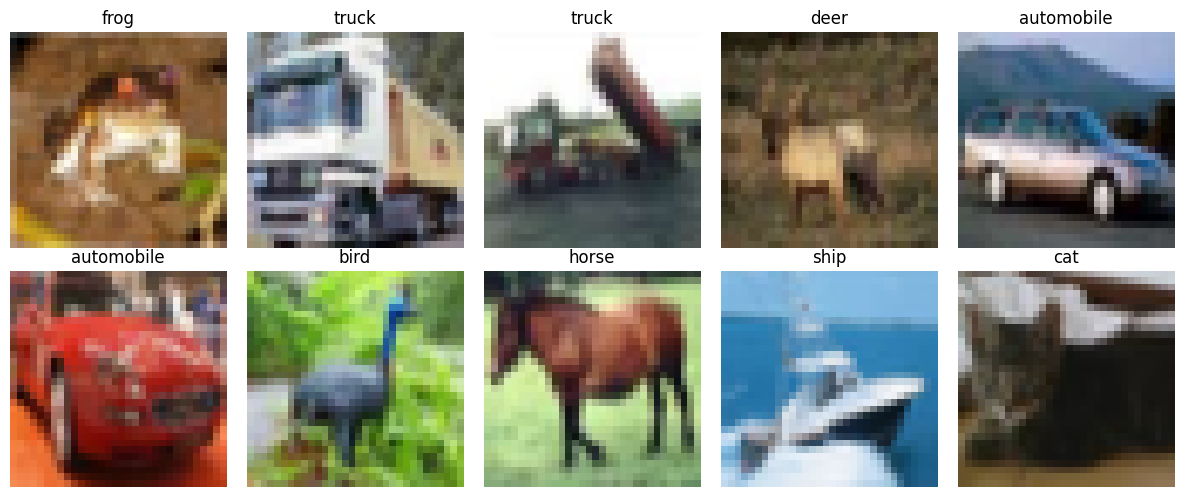

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, index in zip(axes.ravel(), range(10)):
    image, label = train_dataset[index]
    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

**But** : preparer un sous-ensemble raisonnable, normaliser et encoder les labels en one-hot.

**Pourquoi** : CIFAR-10 complet est lourd pour un MLP from scratch pur `numpy`, surtout dans Colab.


In [10]:
TRAIN_SAMPLES = 10000
TEST_SAMPLES = 2000
NUM_CLASSES = 10
SEED = 42

rng = np.random.default_rng(SEED)

train_indices = rng.choice(len(train_dataset), size=TRAIN_SAMPLES, replace=False)
test_indices = rng.choice(len(test_dataset), size=TEST_SAMPLES, replace=False)

def to_numpy_subset(dataset, indices):
    images = []
    labels = []
    for index in indices:
        image, label = dataset[index]
        images.append(np.asarray(image, dtype=np.float32) / 255.0)
        labels.append(label)
    X = np.stack(images)
    y = np.array(labels, dtype=int)
    return X, y

X_train_img, y_train_idx = to_numpy_subset(train_dataset, train_indices)
X_test_img, y_test_idx = to_numpy_subset(test_dataset, test_indices)

X_train = X_train_img.reshape(len(X_train_img), -1)
X_test = X_test_img.reshape(len(X_test_img), -1)

mean = X_train.mean(axis=0, keepdims=True)
std = X_train.std(axis=0, keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

y_train = np.eye(NUM_CLASSES)[y_train_idx]
y_test = np.eye(NUM_CLASSES)[y_test_idx]

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((10000, 3072), (10000, 10), (2000, 3072), (2000, 10))

**But** : definir un MLP multiclasses avec notre framework.

**Pourquoi** : c'est la version la plus fidele a l'etat actuel du projet avant d'avoir des convolutions from scratch.


In [11]:
model = Sequential([
    Dense(input_dim=32 * 32 * 3, output_dim=512, seed=0),
    ReLU(),
    Dense(input_dim=512, output_dim=256, seed=1),
    ReLU(),
    Dense(input_dim=256, output_dim=128, seed=2),
    ReLU(),
    Dense(input_dim=128, output_dim=NUM_CLASSES, seed=3),
    Softmax(),
])

loss = MulticlassCrossEntropy()

optimizer = SGD(lr=1e-4)
model

Sequential(layers=[Dense(input_dim=3072, output_dim=512, seed=0, W=array([[ 0.0032, -0.0034,  0.0163, ..., -0.0181, -0.0074,  0.0036],
       [-0.0139, -0.0034,  0.0331, ...,  0.013 , -0.0274, -0.0085],
       [ 0.0124,  0.0412, -0.02  , ..., -0.011 ,  0.0453, -0.0385],
       ...,
       [-0.0129, -0.0093, -0.0285, ...,  0.0156,  0.0468, -0.0119],
       [ 0.0405,  0.0187,  0.0071, ...,  0.017 , -0.0039, -0.0671],
       [-0.0172,  0.0228,  0.0272, ...,  0.0444, -0.0251,  0.0114]]), b=array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

**But** : entrainer le modele sur train et suivre la performance sur test.

**Pourquoi** : mesurer ce que notre framework sait deja faire sur un vrai benchmark d'images.


In [12]:
history = train_multiclass_classifier(
    model=model,
    X=X_train,
    y=y_train,
    loss=loss,
    optimizer=optimizer,
    epochs=20,
    batch_size=64,
    shuffle=True,
    seed=SEED,
)

history[-1]

EpochMetrics(epoch=19, loss=1.96960136649002, accuracy=0.3005)

**But** : visualiser la loss et l'accuracy train.

**Pourquoi** : verifier la convergence du MLP avant l'evaluation finale sur le test set.


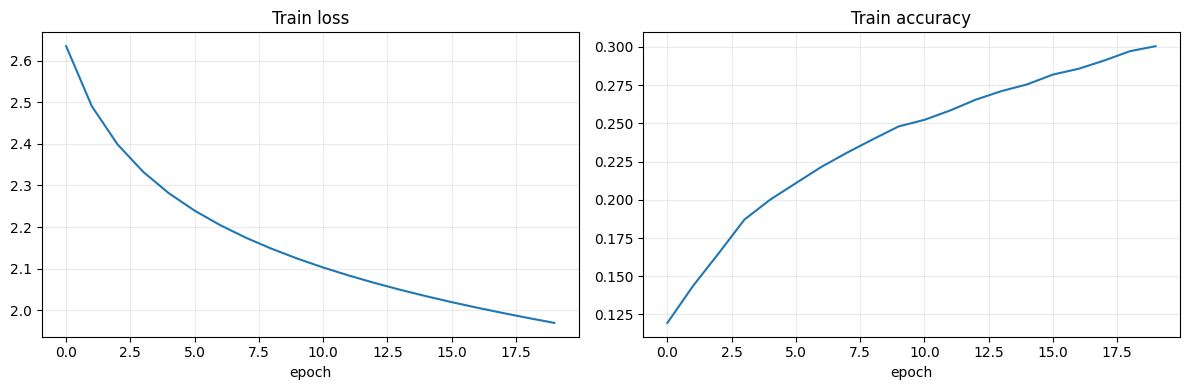

In [13]:
epochs = [row.epoch for row in history]
losses = [row.loss for row in history]
accuracies = [row.accuracy for row in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, losses)
axes[0].set_title('Train loss')
axes[0].set_xlabel('epoch')
axes[0].grid(True, alpha=0.25)

axes[1].plot(epochs, accuracies)
axes[1].set_title('Train accuracy')
axes[1].set_xlabel('epoch')
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


**But** : evaluer le modele sur le test set.

**Pourquoi** : mesurer la generalisation reelle du MLP from scratch sur CIFAR-10.


In [14]:
from src.metrics import multiclass_accuracy

test_probs = model.predict_proba(X_test)
test_acc = multiclass_accuracy(y_test, test_probs)
test_pred_idx = np.argmax(test_probs, axis=1)
test_true_idx = np.argmax(y_test, axis=1)

print('test accuracy =', round(test_acc, 4))

test accuracy = 0.2815


**But** : afficher la matrice de confusion.

**Pourquoi** : voir quelles classes le MLP confond le plus.


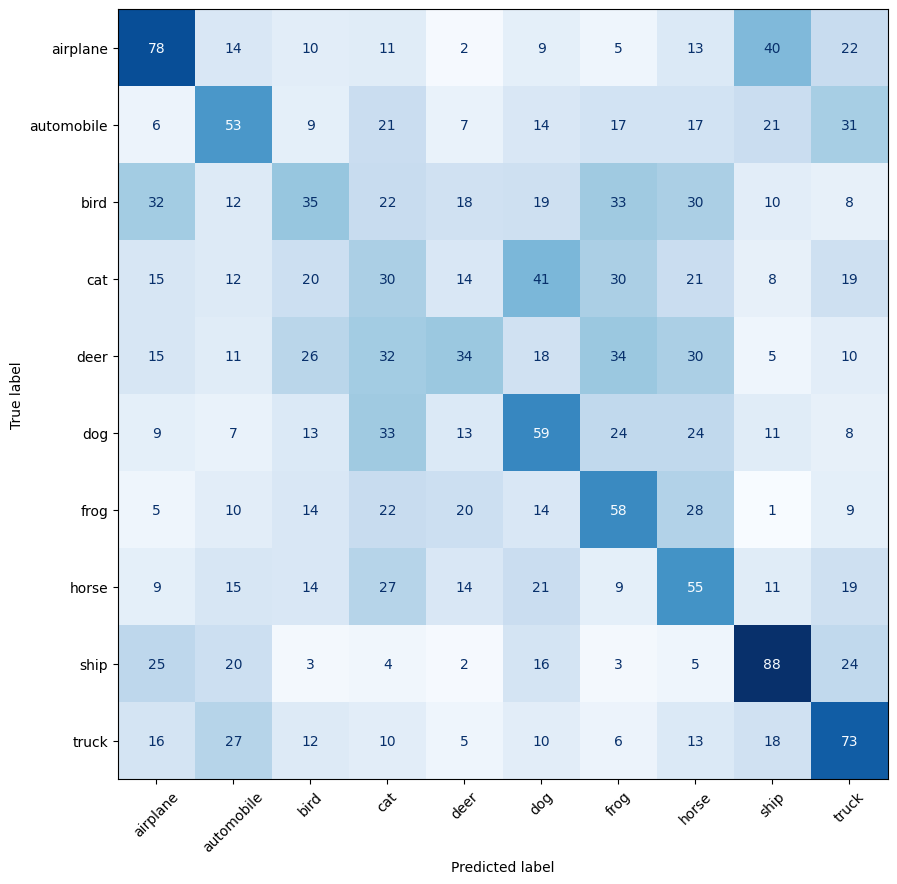

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(test_true_idx, test_pred_idx)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.show()